<a href="https://colab.research.google.com/github/ozodbekrajabboyev/week10_lab_aiml302/blob/main/Lab_RNN_LSTM_GRU_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML302 Deep Learning and Neural Networks
## Lab: RNN, LSTM and GRU for Time-Series Forecasting

**Duration:** 2 hours

| Session | Part | What happens |
|---|---|---|
| Session 1 (first hour) | Part 1: Guided walkthrough | We build, train, tune and compare RNN, LSTM and GRU models together, step by step |
| Session 2 (second hour) | Part 2: Graded exercises | You work on your own: 3 exercises, 100 marks, about 30 minutes |

**Learning outcomes.** By the end of this lab you should be able to:

1. Explain what time-series forecasting is and why the order of the data matters.
2. Turn a time series into input/target pairs using a sliding window.
3. Build RNN, LSTM and GRU models in PyTorch.
4. Train the models, measure their error (RMSE, MAE) and compare them fairly.
5. Tune simple hyperparameters such as hidden size and window size.


---
# Part 1: Guided Walkthrough

**Plan for this hour**

1. Setup
2. What is time-series forecasting?
3. Create the dataset
4. Split the data (train / validation / test)
5. Scale the data
6. Sliding windows: turning a series into examples
7. The simple RNN
8. LSTM and GRU
9. One model class for all three
10. Training and evaluation tools
11. Train the three models
12. Compare the results
13. Tuning the models
14. Final test
15. Summary

## 1. Setup

We import the libraries we need:

- `numpy` for arrays and maths
- `pandas` for result tables
- `matplotlib` for plots
- `torch` (PyTorch) for building and training neural networks

We also fix the **random seed**. Neural networks start with random weights, so every run gives slightly different results. Fixing the seed makes results repeatable, so everyone in the class sees the same numbers.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(42)
plt.rcParams["figure.figsize"] = (12, 4)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


## 2. What is time-series forecasting?

A **time series** is a list of values recorded in time order, for example:

- the temperature in Tashkent every day
- the number of customers in a shop every hour
- the electricity used by a city every day

**Forecasting** means using the past values to predict the next value.

```
Past values:   day 1, day 2, ..., day 30   ->   model   ->   prediction for day 31
```

Two things make time series different from normal tables of data:

1. **Order matters.** Day 5 comes after day 4. If we shuffle the rows, we destroy the information.
2. **The future must never leak into the past.** When we train, the model may only see values from *before* the day it predicts.

Recurrent networks (RNN, LSTM, GRU) are designed for this kind of ordered data. They read the values one step at a time and keep a short "memory" of what they have seen.

## 3. Create the dataset

To keep the lab simple and working without internet, we create a realistic **daily temperature** series for 4 years (1460 days). It has three parts:

| Part | Meaning | How we make it |
|---|---|---|
| Seasonal pattern | Hot summers, cold winters, repeats every 365 days | a sine wave |
| Trend | Temperature slowly rising over the years | a small straight line |
| Noise | Random day-to-day changes | random numbers |

Real data (sales, weather, energy) usually has these same three parts.

In [2]:
n_days = 1460                      # 4 years of daily data
t = np.arange(n_days)              # 0, 1, 2, ..., 1459

seasonal = 12 * np.sin(2 * np.pi * (t - 100) / 365)   # yearly cycle
trend    = 0.002 * t                                    # slow warming
noise    = np.random.normal(0, 2, n_days)               # random daily change

temperature = 15 + seasonal + trend + noise

print("Number of days:", len(temperature))
print("First 5 values:", np.round(temperature[:5], 2))

Number of days: 1460
First 5 values: [4.13 2.83 4.38 6.11 2.58]


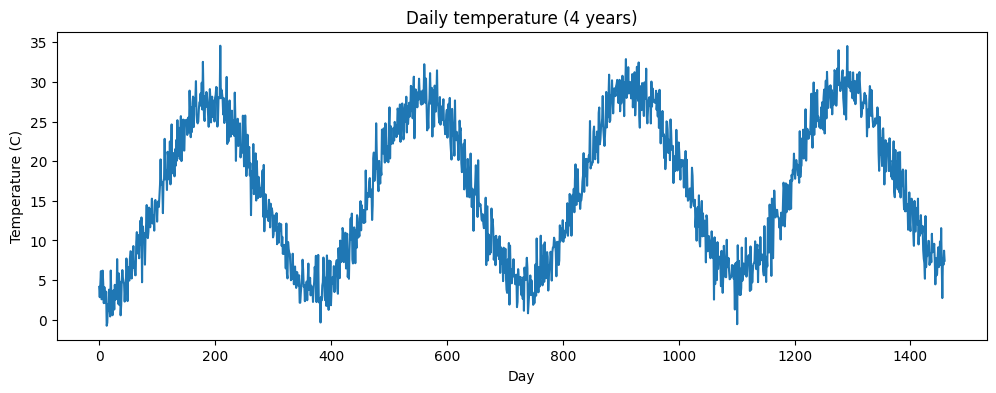

In [3]:
plt.plot(temperature)
plt.title("Daily temperature (4 years)")
plt.xlabel("Day")
plt.ylabel("Temperature (C)")
plt.show()

**What to notice:** the yearly up-and-down cycle, the small random noise on top, and the slow rise over the 4 years.

## 4. Split the data: train / validation / test

We split the series into three parts **in time order** (no shuffling):

```
|<------------ train 70% ------------>|<-- validation 15% -->|<-- test 15% -->|
 day 0                                                                  day 1459
```

| Part | Used for |
|---|---|
| Train | The model learns its weights from this part |
| Validation | We use it to **compare** models and **choose** settings (tuning) |
| Test | Used **once at the very end** to report the final result |

Why keep the test set separate? If we keep checking the test set while tuning, we start choosing settings that suit the test set, and the final result becomes too optimistic.

In [4]:
n = len(temperature)
train_end = int(0.70 * n)
val_end   = int(0.85 * n)

train_data = temperature[:train_end]
val_data   = temperature[train_end:val_end]
test_data  = temperature[val_end:]

print("Train size:", len(train_data))
print("Validation size:", len(val_data))
print("Test size:", len(test_data))

Train size: 1021
Validation size: 220
Test size: 219


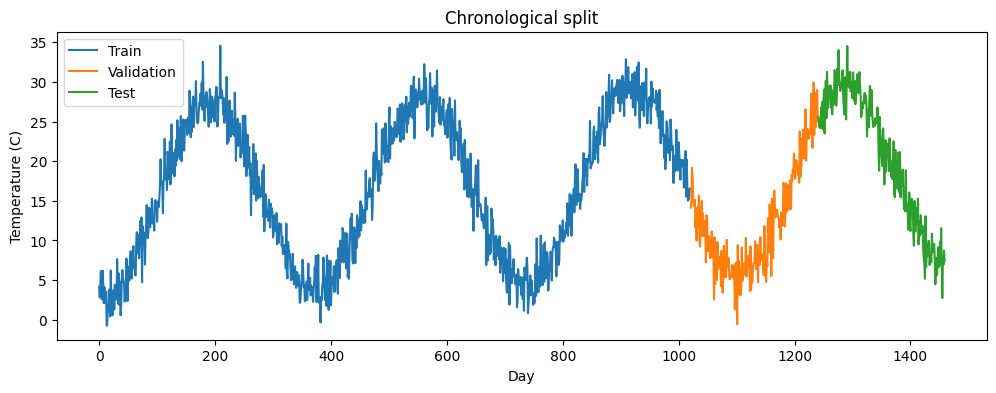

In [5]:
plt.plot(range(0, train_end), train_data, label="Train")
plt.plot(range(train_end, val_end), val_data, label="Validation")
plt.plot(range(val_end, n), test_data, label="Test")
plt.title("Chronological split")
plt.xlabel("Day")
plt.ylabel("Temperature (C)")
plt.legend()
plt.show()

## 5. Scale the data

Neural networks train better when the numbers are small, roughly between 0 and 1. We use **min-max scaling**:

$$x_{scaled} = \frac{x - \min}{\max - \min}$$

**Important rule:** take the min and max from the **training data only**. The model must not know anything about the future (validation and test) during training.

Later, to read predictions in degrees again, we reverse the scaling:

$$x = x_{scaled} \times (\max - \min) + \min$$

In [6]:
data_min = train_data.min()
data_max = train_data.max()

def scale(x, data_min, data_max):
    return (x - data_min) / (data_max - data_min)

def unscale(x, data_min, data_max):
    return x * (data_max - data_min) + data_min

train_scaled = scale(train_data, data_min, data_max)
val_scaled   = scale(val_data,   data_min, data_max)
test_scaled  = scale(test_data,  data_min, data_max)

print("Train min / max (C):", round(data_min, 2), "/", round(data_max, 2))
print("Scaled train range:", round(train_scaled.min(), 2), "to", round(train_scaled.max(), 2))

Train min / max (C): -0.77 / 34.57
Scaled train range: 0.0 to 1.0


Validation and test values can be slightly below 0 or above 1 (because of the warming trend). That is fine.

## 6. Sliding windows: turning a series into examples

A neural network needs pairs of **input (X)** and **target (y)**. We make them with a **sliding window**:

- take `window_size` values in a row as the input
- the value right after them is the target
- move one step forward and repeat

Small example with `window_size = 3`:

```
Series:  10  20  30  40  50  60

X (input)        y (target)
[10, 20, 30]  ->  40
[20, 30, 40]  ->  50
[30, 40, 50]  ->  60
```

In [7]:
def create_windows(series, window_size):
    X, y = [], []
    for i in range(len(series) - window_size):
        X.append(series[i : i + window_size])   # the window
        y.append(series[i + window_size])       # the next value
    return np.array(X), np.array(y)

# Try it on the small example
small_series = np.array([10, 20, 30, 40, 50, 60])
X_small, y_small = create_windows(small_series, window_size=3)
print("X =\n", X_small)
print("y =", y_small)

X =
 [[10 20 30]
 [20 30 40]
 [30 40 50]]
y = [40 50 60]


Now we apply it to our temperature data with a window of **30 days**: the model looks at the last 30 days to predict the next day.

PyTorch recurrent layers expect the input shape **(samples, time steps, features)**:

| Dimension | Meaning | Our value |
|---|---|---|
| samples | number of windows | depends on the split |
| time steps | length of each window | 30 |
| features | values per time step | 1 (only temperature) |

`unsqueeze(-1)` adds the last "features" dimension of size 1.

In [8]:
WINDOW = 30

X_train, y_train = create_windows(train_scaled, WINDOW)
X_val,   y_val   = create_windows(val_scaled,   WINDOW)
X_test,  y_test  = create_windows(test_scaled,  WINDOW)

def to_tensors(X, y):
    X = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)   # (samples, time steps, 1)
    y = torch.tensor(y, dtype=torch.float32).unsqueeze(-1)   # (samples, 1)
    return X, y

X_train, y_train = to_tensors(X_train, y_train)
X_val,   y_val   = to_tensors(X_val,   y_val)
X_test,  y_test  = to_tensors(X_test,  y_test)

print("X_train:", X_train.shape, "  y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "  y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "  y_test: ", y_test.shape)

X_train: torch.Size([991, 30, 1])   y_train: torch.Size([991, 1])
X_val:   torch.Size([190, 30, 1])   y_val:   torch.Size([190, 1])
X_test:  torch.Size([189, 30, 1])   y_test:  torch.Size([189, 1])


Each split loses its first 30 days, because the first window needs 30 past values. This keeps the three splits fully separate.

## 7. The simple RNN

A normal (dense) network looks at all inputs at once and has no idea of order. A **Recurrent Neural Network (RNN)** reads the sequence **one step at a time** and carries a **hidden state** $h$ from one step to the next. The hidden state is the network's memory.

At each time step $t$:

$$h_t = \tanh(W_x \, x_t + W_h \, h_{t-1} + b)$$

- $x_t$ is the value at this step (today's temperature)
- $h_{t-1}$ is the memory from the previous step
- $h_t$ is the new memory
- the **same weights** $W_x, W_h, b$ are used at every step

```
x1 -> [RNN] -> h1 -> [RNN] -> h2 -> [RNN] -> h3 ... -> h30 -> [Linear] -> prediction
       ^              ^               ^
       x1             x2              x3
```

After reading all 30 days, the last hidden state $h_{30}$ is a summary of the window. A small **Linear** layer turns it into one number: the forecast.

**The weakness of the simple RNN: vanishing gradients.** During training the error signal travels backwards through all 30 steps. At each step it is multiplied by small numbers, so it becomes tiny for the early steps. The result: a simple RNN has trouble remembering things from far back in the sequence.

Let us see what a PyTorch RNN layer returns.

In [9]:
rnn_layer = nn.RNN(input_size=1, hidden_size=8, batch_first=True)

example_input = torch.randn(4, 30, 1)          # 4 windows, 30 steps, 1 feature
output, h_last = rnn_layer(example_input)

print("Input shape: ", example_input.shape)
print("Output shape:", output.shape, " -> hidden state at every step")
print("h_last shape:", h_last.shape, " -> hidden state at the last step only")

Input shape:  torch.Size([4, 30, 1])
Output shape: torch.Size([4, 30, 8])  -> hidden state at every step
h_last shape: torch.Size([1, 4, 8])  -> hidden state at the last step only


- `output` has the hidden state for **all 30 steps**: shape (4, 30, 8).
- We only need the **last step** for forecasting: `output[:, -1, :]` with shape (4, 8).
- `batch_first=True` means the first dimension is samples. Always use it in this course; it matches the shape table above.

## 8. LSTM and GRU

LSTM and GRU are improved RNNs. They add **gates**: small learnable switches with values between 0 and 1 that decide what to keep and what to forget. Gates let useful information (and the error signal during training) travel through many steps without disappearing.

### LSTM (Long Short-Term Memory)

An LSTM keeps two memories: the **cell state** $c_t$ (long-term memory) and the **hidden state** $h_t$ (short-term memory / output). You can think of the cell state as a conveyor belt that carries information forward, with three gates controlling it:

| Gate | Question it answers |
|---|---|
| Forget gate | How much of the old long-term memory should I keep? |
| Input gate | How much of the new information should I write into memory? |
| Output gate | How much of the memory should I show as output now? |

### GRU (Gated Recurrent Unit)

A GRU is a simpler version of the LSTM. It has **no separate cell state** and only **two gates**:

| Gate | Question it answers |
|---|---|
| Update gate | How much of the old memory should I keep, and how much new information should I add? |
| Reset gate | How much of the old memory should I use when creating the new information? |

### Quick comparison

| | Simple RNN | LSTM | GRU |
|---|---|---|---|
| Gates | 0 | 3 | 2 |
| Memories | hidden state | hidden state + cell state | hidden state |
| Parameters (same hidden size) | fewest | most (about 4x RNN) | middle (about 3x RNN) |
| Long sequences | weak | strong | strong |
| Speed | fastest | slowest | middle |

In PyTorch all three are used in the same way. The only difference: an LSTM returns `(h, c)` instead of just `h` as its second output. We ignore the second output anyway.

## 9. One model class for all three

To compare the three models **fairly**, we build them with the same structure. Only the recurrent layer changes:

```
input (samples, 30, 1) -> RNN / LSTM / GRU -> last hidden state -> Linear -> prediction (samples, 1)
```

The argument `cell_type` chooses which recurrent layer to use.

In [10]:
class Forecaster(nn.Module):
    def __init__(self, cell_type="RNN", hidden_size=32, num_layers=1):
        super().__init__()
        if cell_type == "RNN":
            self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size,
                              num_layers=num_layers, batch_first=True)
        elif cell_type == "LSTM":
            self.rnn = nn.LSTM(input_size=1, hidden_size=hidden_size,
                               num_layers=num_layers, batch_first=True)
        elif cell_type == "GRU":
            self.rnn = nn.GRU(input_size=1, hidden_size=hidden_size,
                              num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.rnn(x)          # output: (samples, time steps, hidden_size)
        last_step = output[:, -1, :]     # keep only the last time step
        return self.fc(last_step)        # (samples, 1)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

for cell in ["RNN", "LSTM", "GRU"]:
    m = Forecaster(cell, hidden_size=32)
    print(cell, "parameters:", count_parameters(m))

RNN parameters: 1153
LSTM parameters: 4513
GRU parameters: 3393


Notice the parameter counts: the LSTM is about 4 times bigger than the RNN, and the GRU about 3 times. This matches the table in Section 8.

## 10. Training and evaluation tools

### Training

The training loop is the same as in earlier labs:

1. Predict with the model (forward pass)
2. Compute the loss: **Mean Squared Error (MSE)** between prediction and true value
3. Compute the gradients (`loss.backward()`)
4. Update the weights (`optimizer.step()`)
5. Repeat for many **epochs**

Our dataset is small, so we give **all training windows at once** in each epoch (no mini-batches). This keeps the code short.

In [11]:
def train_model(model, X_train, y_train, epochs=100, lr=0.01, print_every=25):
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()            # 1. clear old gradients
        pred = model(X_train)            # 2. forward pass
        loss = loss_fn(pred, y_train)    # 3. compute loss
        loss.backward()                  # 4. compute gradients
        optimizer.step()                 # 5. update weights
        losses.append(loss.item())

        if print_every and (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch + 1:3d}/{epochs}   train loss: {loss.item():.5f}")
    return losses

### Evaluation

We measure the error in **degrees C** (after unscaling), so the numbers are easy to understand:

| Metric | Formula | Meaning |
|---|---|---|
| MAE (Mean Absolute Error) | average of $\lvert y - \hat{y} \rvert$ | "On average, the forecast is wrong by this many degrees" |
| RMSE (Root Mean Squared Error) | $\sqrt{\text{average of } (y - \hat{y})^2}$ | Like MAE, but punishes big mistakes more |

For both: **lower is better**.

`model.eval()` and `torch.no_grad()` tell PyTorch that we are only predicting, not training.

In [12]:
def evaluate(model, X, y, data_min, data_max):
    model.eval()
    with torch.no_grad():
        pred = model(X).numpy().flatten()
    true = y.numpy().flatten()

    pred = unscale(pred, data_min, data_max)      # back to original units
    true = unscale(true, data_min, data_max)

    rmse = np.sqrt(np.mean((true - pred) ** 2))
    mae  = np.mean(np.abs(true - pred))
    return pred, true, rmse, mae

### A simple baseline

Before we trust a deep learning model, we compare it with a very simple rule: **"tomorrow will be the same as today"**. This is called the **naive forecast**. If our network cannot beat it, the network is not useful.

In [13]:
def naive_forecast(X, y, data_min, data_max):
    pred = X[:, -1, 0].numpy()             # last value of each window
    true = y.numpy().flatten()
    pred = unscale(pred, data_min, data_max)
    true = unscale(true, data_min, data_max)
    rmse = np.sqrt(np.mean((true - pred) ** 2))
    mae  = np.mean(np.abs(true - pred))
    return rmse, mae

naive_rmse, naive_mae = naive_forecast(X_val, y_val, data_min, data_max)
print(f"Naive forecast on validation:  RMSE = {naive_rmse:.3f} C   MAE = {naive_mae:.3f} C")

Naive forecast on validation:  RMSE = 3.137 C   MAE = 2.402 C


## 11. Train the three models

We now train RNN, LSTM and GRU with the **same settings**:

| Setting | Value |
|---|---|
| Window size | 30 days |
| Hidden size | 32 |
| Layers | 1 |
| Epochs | 100 |
| Learning rate | 0.01 |

We reset the seed before each model so they all start in a comparable way.

### 11.1 Simple RNN

In [14]:
set_seed(42)
rnn_model = Forecaster("RNN", hidden_size=32)

start = time.time()
rnn_losses = train_model(rnn_model, X_train, y_train, epochs=100, lr=0.01)
rnn_time = time.time() - start

rnn_pred, val_true, rnn_rmse, rnn_mae = evaluate(rnn_model, X_val, y_val, data_min, data_max)
print(f"\nRNN  ->  validation RMSE = {rnn_rmse:.3f} C   MAE = {rnn_mae:.3f} C   time = {rnn_time:.1f} s")

Epoch  25/100   train loss: 0.00627
Epoch  50/100   train loss: 0.00444
Epoch  75/100   train loss: 0.00401
Epoch 100/100   train loss: 0.00392

RNN  ->  validation RMSE = 2.361 C   MAE = 1.802 C   time = 8.9 s


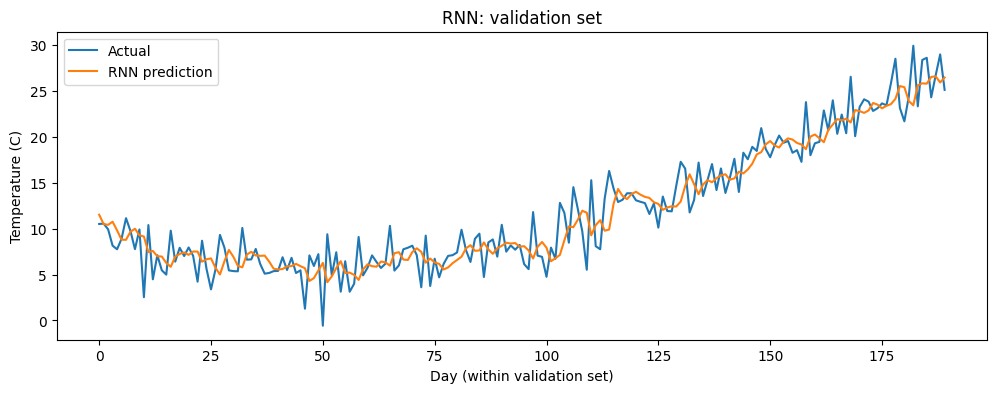

In [15]:
plt.plot(val_true, label="Actual")
plt.plot(rnn_pred, label="RNN prediction")
plt.title("RNN: validation set")
plt.xlabel("Day (within validation set)")
plt.ylabel("Temperature (C)")
plt.legend()
plt.show()

The prediction follows the seasonal pattern well. It cannot predict the random noise; no model can, because noise is random by definition.

### 11.2 LSTM

In [16]:
set_seed(42)
lstm_model = Forecaster("LSTM", hidden_size=32)

start = time.time()
lstm_losses = train_model(lstm_model, X_train, y_train, epochs=100, lr=0.01)
lstm_time = time.time() - start

lstm_pred, _, lstm_rmse, lstm_mae = evaluate(lstm_model, X_val, y_val, data_min, data_max)
print(f"\nLSTM ->  validation RMSE = {lstm_rmse:.3f} C   MAE = {lstm_mae:.3f} C   time = {lstm_time:.1f} s")

Epoch  25/100   train loss: 0.01926
Epoch  50/100   train loss: 0.00464
Epoch  75/100   train loss: 0.00381
Epoch 100/100   train loss: 0.00377

LSTM ->  validation RMSE = 2.304 C   MAE = 1.761 C   time = 9.1 s


### 11.3 GRU

In [17]:
set_seed(42)
gru_model = Forecaster("GRU", hidden_size=32)

start = time.time()
gru_losses = train_model(gru_model, X_train, y_train, epochs=100, lr=0.01)
gru_time = time.time() - start

gru_pred, _, gru_rmse, gru_mae = evaluate(gru_model, X_val, y_val, data_min, data_max)
print(f"\nGRU  ->  validation RMSE = {gru_rmse:.3f} C   MAE = {gru_mae:.3f} C   time = {gru_time:.1f} s")

Epoch  25/100   train loss: 0.00922
Epoch  50/100   train loss: 0.00426
Epoch  75/100   train loss: 0.00376
Epoch 100/100   train loss: 0.00373

GRU  ->  validation RMSE = 2.299 C   MAE = 1.768 C   time = 5.0 s


## 12. Compare the results

### 12.1 Results table

In [18]:
results = pd.DataFrame({
    "Model":      ["Naive", "RNN", "LSTM", "GRU"],
    "Val RMSE":   [naive_rmse, rnn_rmse, lstm_rmse, gru_rmse],
    "Val MAE":    [naive_mae,  rnn_mae,  lstm_mae,  gru_mae],
    "Parameters": [0, count_parameters(rnn_model), count_parameters(lstm_model), count_parameters(gru_model)],
    "Train time (s)": [0, rnn_time, lstm_time, gru_time],
})
results.round(3)

,Model,Val RMSE,Val MAE,Parameters,Train time (s)
0,Naive,3.137,2.402,0,0.000
1,RNN,2.361,1.802,1153,8.869
2,LSTM,2.304,1.761,4513,9.054
3,GRU,2.299,1.768,3393,5.001


### 12.2 Training loss curves

The loss curve shows how fast each model learns. A **log scale** on the y-axis makes small differences easier to see.

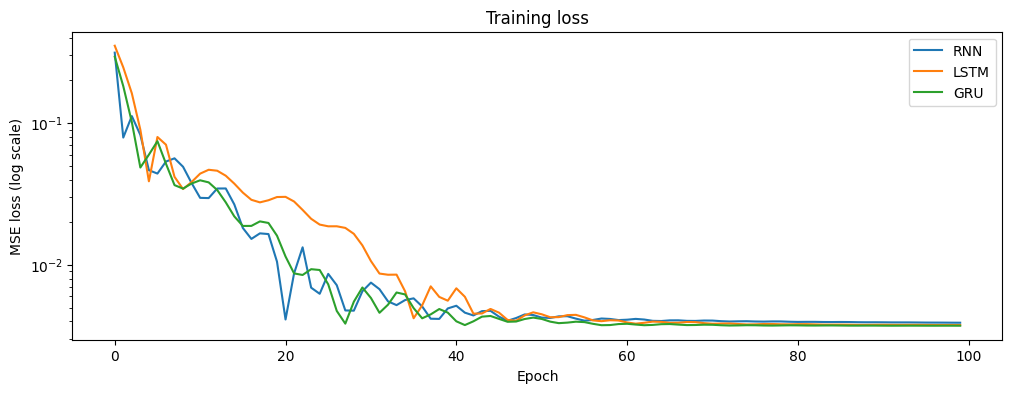

In [19]:
plt.plot(rnn_losses,  label="RNN")
plt.plot(lstm_losses, label="LSTM")
plt.plot(gru_losses,  label="GRU")
plt.yscale("log")
plt.title("Training loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (log scale)")
plt.legend()
plt.show()

### 12.3 Predictions side by side

We zoom in on the first 100 validation days so the differences are visible.

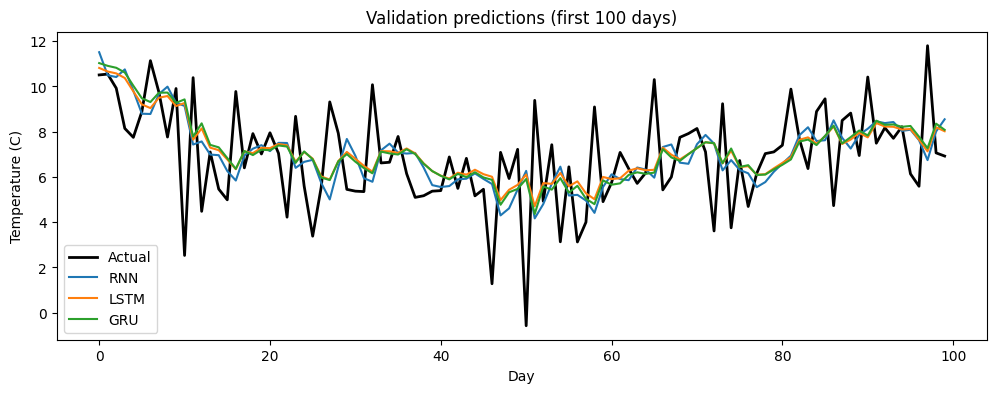

In [20]:
days = 100
plt.plot(val_true[:days],  label="Actual", color="black", linewidth=2)
plt.plot(rnn_pred[:days],  label="RNN")
plt.plot(lstm_pred[:days], label="LSTM")
plt.plot(gru_pred[:days],  label="GRU")
plt.title("Validation predictions (first 100 days)")
plt.xlabel("Day")
plt.ylabel("Temperature (C)")
plt.legend()
plt.show()

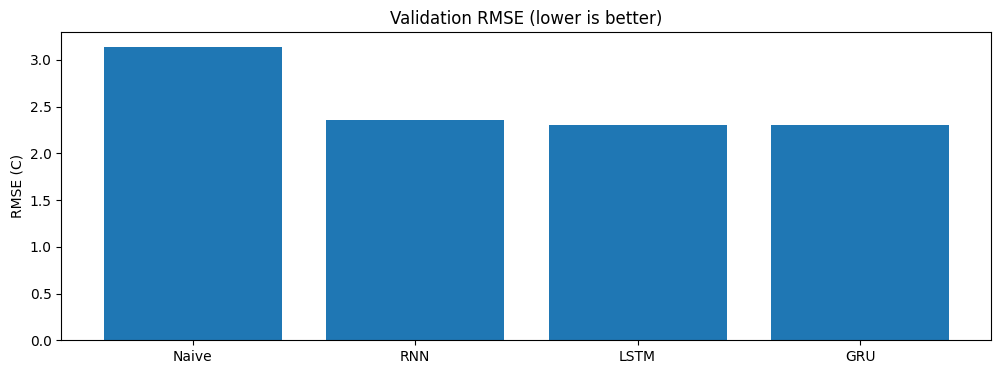

In [21]:
plt.bar(results["Model"], results["Val RMSE"])
plt.title("Validation RMSE (lower is better)")
plt.ylabel("RMSE (C)")
plt.show()

### 12.4 How to read these results

Discuss with the class:

1. **Did every network beat the naive forecast?** If yes, the networks learned something useful.
2. **Which model has the lowest RMSE?** Look at how big the difference is. A difference of 0.05 C is very small; it may change with a different random seed.
3. **Cost.** LSTM has the most parameters and is usually the slowest. GRU is often almost as good with fewer parameters.
4. **Why are the models so close here?** The noise we added has a standard deviation of 2 C. Noise is random, so even a perfect model would still have an RMSE of about 2 C. All three models are already close to this limit. Also, our series is simple and the window is only 30 days. The advantage of LSTM and GRU appears mainly with **long** windows and long-term patterns. We test this in the next section.

There is no model that always wins. That is why we **compare** models on our own data.

## 13. Tuning the models

**Hyperparameters** are settings we choose before training. The network does not learn them. Common ones for recurrent models:

| Hyperparameter | What it controls | Too small | Too large |
|---|---|---|---|
| Window size | How many past days the model sees | Misses longer patterns | Slower, harder to train (for RNN) |
| Hidden size | Size of the memory | Cannot learn the pattern (underfitting) | Slow, may overfit |
| Number of layers | Depth of the network | Too simple | Slower, harder to train |
| Learning rate | Size of each weight update | Learns very slowly | Loss jumps around, unstable |
| Epochs | How long we train | Underfitting | Overfitting, wasted time |

**The tuning rule:** change **one** setting at a time, keep everything else fixed, and compare on the **validation** set.

### 13.1 Experiment 1: hidden size

We try three hidden sizes for the GRU.

In [22]:
hidden_results = []

for hidden in [8, 32, 64]:
    set_seed(42)
    model = Forecaster("GRU", hidden_size=hidden)
    train_model(model, X_train, y_train, epochs=100, lr=0.01, print_every=0)
    _, _, rmse, mae = evaluate(model, X_val, y_val, data_min, data_max)
    hidden_results.append([hidden, count_parameters(model), rmse, mae])
    print(f"hidden_size = {hidden:3d}   val RMSE = {rmse:.3f}")

pd.DataFrame(hidden_results, columns=["Hidden size", "Parameters", "Val RMSE", "Val MAE"]).round(3)

hidden_size =   8   val RMSE = 2.288
hidden_size =  32   val RMSE = 2.299
hidden_size =  64   val RMSE = 2.290


,Hidden size,Parameters,Val RMSE,Val MAE
0,8,273,2.288,1.758
1,32,3393,2.299,1.768
2,64,12929,2.290,1.762


Look at whether a bigger memory always helps. Compare the number of parameters with the change in RMSE. Often, after a certain size, the error stops improving while the model keeps getting bigger and slower. When two models have almost the same error, choose the smaller one.

### 13.2 Experiment 2: window size (RNN vs LSTM vs GRU)

Now we change the window size. A longer window means the model must remember information from further back. In theory, this is where the simple RNN struggles. Let us check whether our results show it.

The windows must be created again for every window size, so we put the steps in a small helper function.

In [23]:
def make_dataset(window_size):
    Xtr, ytr = to_tensors(*create_windows(train_scaled, window_size))
    Xva, yva = to_tensors(*create_windows(val_scaled,   window_size))
    return Xtr, ytr, Xva, yva

window_results = []

for window in [7, 30, 90]:
    Xtr, ytr, Xva, yva = make_dataset(window)
    for cell in ["RNN", "LSTM", "GRU"]:
        set_seed(42)
        model = Forecaster(cell, hidden_size=32)
        train_model(model, Xtr, ytr, epochs=100, lr=0.01, print_every=0)
        _, _, rmse, _ = evaluate(model, Xva, yva, data_min, data_max)
        window_results.append([window, cell, rmse])
        print(f"window = {window:3d}   {cell:4s}   val RMSE = {rmse:.3f}")

window =   7   RNN    val RMSE = 2.378
window =   7   LSTM   val RMSE = 2.304
window =   7   GRU    val RMSE = 2.319
window =  30   RNN    val RMSE = 2.361
window =  30   LSTM   val RMSE = 2.304
window =  30   GRU    val RMSE = 2.299
window =  90   RNN    val RMSE = 2.350
window =  90   LSTM   val RMSE = 2.308
window =  90   GRU    val RMSE = 2.290


In [25]:
window_table = pd.DataFrame(window_results, columns=["Window", "Model", "Val RMSE"])
window_table.pivot(index="Window", columns="Model", values="Val RMSE").round(3)

Model,GRU,LSTM,RNN
Window,,,
7,2.319,2.304,2.378
30,2.299,2.304,2.361
90,2.290,2.308,2.350


**How to read the table:** each row is one window size, each column one model. Compare how the RNN column changes as the window grows, and compare it with the LSTM and GRU columns.

The validation set is small, so small differences between numbers can come from random chance. Look for clear patterns, not tiny differences.

## 14. Final test

We have finished comparing and tuning on the validation set. Now we use the **test set once** to report the final, honest result for the three models from Section 11 (window 30, hidden size 32).

In [26]:
final_rows = []
naive_test_rmse, naive_test_mae = naive_forecast(X_test, y_test, data_min, data_max)
final_rows.append(["Naive", naive_test_rmse, naive_test_mae])

test_predictions = {}
for name, model in [("RNN", rnn_model), ("LSTM", lstm_model), ("GRU", gru_model)]:
    pred, test_true, rmse, mae = evaluate(model, X_test, y_test, data_min, data_max)
    test_predictions[name] = pred
    final_rows.append([name, rmse, mae])

pd.DataFrame(final_rows, columns=["Model", "Test RMSE", "Test MAE"]).round(3)

,Model,Test RMSE,Test MAE
0,Naive,2.718,2.195
1,RNN,2.217,1.748
2,LSTM,2.143,1.695
3,GRU,2.150,1.709


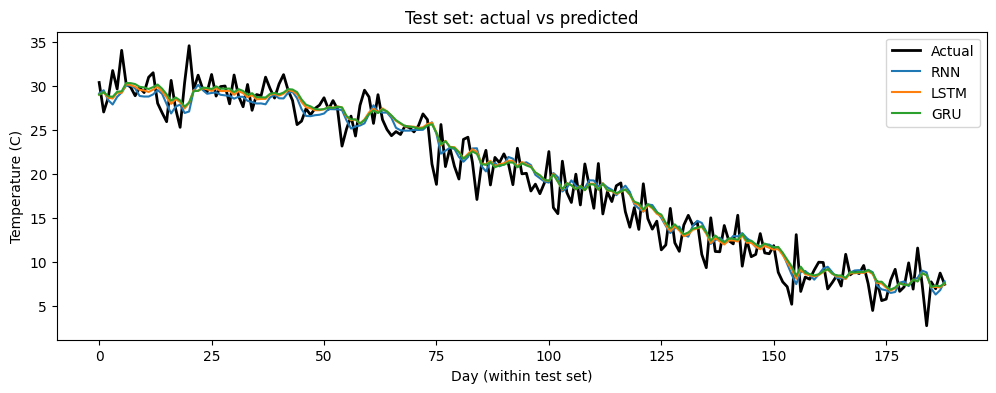

In [27]:
plt.plot(test_true, label="Actual", color="black", linewidth=2)
for name, pred in test_predictions.items():
    plt.plot(pred, label=name)
plt.title("Test set: actual vs predicted")
plt.xlabel("Day (within test set)")
plt.ylabel("Temperature (C)")
plt.legend()
plt.show()

## 15. Summary

| Step | Key idea |
|---|---|
| Split | Always split in **time order**. Never shuffle a time series before splitting. |
| Scale | Use the min and max of the **training set only**. |
| Windows | Past `window_size` values -> next value. Input shape: (samples, time steps, features). |
| RNN | Reads one step at a time with a hidden state. Simple, fast, but forgets long-range information (vanishing gradients). |
| LSTM | 3 gates + cell state. Best at long memory, most parameters. |
| GRU | 2 gates, no cell state. Usually close to LSTM, with fewer parameters. |
| Evaluate | Report RMSE and MAE in original units. Always compare with a naive baseline. |
| Tune | Change one setting at a time, choose using the validation set, use the test set only once at the end. |

In Part 2 you will repeat these steps on a new dataset on your own.

---
# Part 2: Graded Exercises (100 marks)

**Time:** about 30 minutes. Work on your own.

**Dataset:** daily **electricity demand** of a city for 3 years (in megawatts, MW). It has a yearly pattern, a weekly pattern (lower demand at weekends), a slow upward trend and noise.

| Exercise | Topic | Marks |
|---|---|---|
| Exercise 1 | Prepare the data | 30 |
| Exercise 2 | Train and compare RNN, LSTM and GRU | 40 |
| Exercise 3 | Tune, test and explain | 30 |
| **Total** | | **100** |

**Rules**

- Write your code where you see `# YOUR CODE HERE`. Replace every `None` with your answer.
- Write text answers in the cells marked **Your answer**.
- You may copy and adapt code from Part 1. That is expected.
- Do not change the dataset cell.
- **Before submitting:** rename the file to `AIML302_Lab_<YourName>_<StudentID>.ipynb`, then run every cell from top to bottom (Runtime > Restart and run all in Colab, or Kernel > Restart and Run All in Jupyter) and check that there are no errors.

### Setup cell (run first, do not change)

This cell contains the same tools you used in Part 1, so Part 2 also works if you open the notebook fresh: `set_seed`, `scale`, `unscale`, `create_windows`, `to_tensors`, `Forecaster`, `count_parameters`, `train_model`, `evaluate`.

In [28]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
plt.rcParams["figure.figsize"] = (12, 4)

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)

def scale(x, data_min, data_max):
    return (x - data_min) / (data_max - data_min)

def unscale(x, data_min, data_max):
    return x * (data_max - data_min) + data_min

def create_windows(series, window_size):
    X, y = [], []
    for i in range(len(series) - window_size):
        X.append(series[i : i + window_size])
        y.append(series[i + window_size])
    return np.array(X), np.array(y)

def to_tensors(X, y):
    X = torch.tensor(X, dtype=torch.float32).unsqueeze(-1)
    y = torch.tensor(y, dtype=torch.float32).unsqueeze(-1)
    return X, y

class Forecaster(nn.Module):
    def __init__(self, cell_type="RNN", hidden_size=32, num_layers=1):
        super().__init__()
        if cell_type == "RNN":
            self.rnn = nn.RNN(1, hidden_size, num_layers=num_layers, batch_first=True)
        elif cell_type == "LSTM":
            self.rnn = nn.LSTM(1, hidden_size, num_layers=num_layers, batch_first=True)
        elif cell_type == "GRU":
            self.rnn = nn.GRU(1, hidden_size, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.rnn(x)
        return self.fc(output[:, -1, :])

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

def train_model(model, X_train, y_train, epochs=100, lr=0.01, print_every=0):
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        loss = loss_fn(model(X_train), y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if print_every and (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch + 1}/{epochs}  loss: {loss.item():.5f}")
    return losses

def evaluate(model, X, y, data_min, data_max):
    model.eval()
    with torch.no_grad():
        pred = model(X).numpy().flatten()
    true = y.numpy().flatten()
    pred = unscale(pred, data_min, data_max)
    true = unscale(true, data_min, data_max)
    rmse = np.sqrt(np.mean((true - pred) ** 2))
    mae = np.mean(np.abs(true - pred))
    return pred, true, rmse, mae

print("Setup complete.")

Setup complete.


### Dataset cell (run, do not change)

In [29]:
set_seed(7)
n_days = 1095                                   # 3 years
t = np.arange(n_days)
yearly = 100 * np.sin(2 * np.pi * t / 365)      # yearly cycle
weekly = 40 * np.sin(2 * np.pi * t / 7)         # weekly cycle
trend  = 0.05 * t                               # slow growth
noise  = np.random.normal(0, 15, n_days)

demand = 500 + yearly + weekly + trend + noise
print("Number of days:", len(demand))

Number of days: 1095


---
## Exercise 1: Prepare the data (30 marks)

**1a. (5 marks)** Plot the `demand` series. Add a title, an x-axis label and a y-axis label.

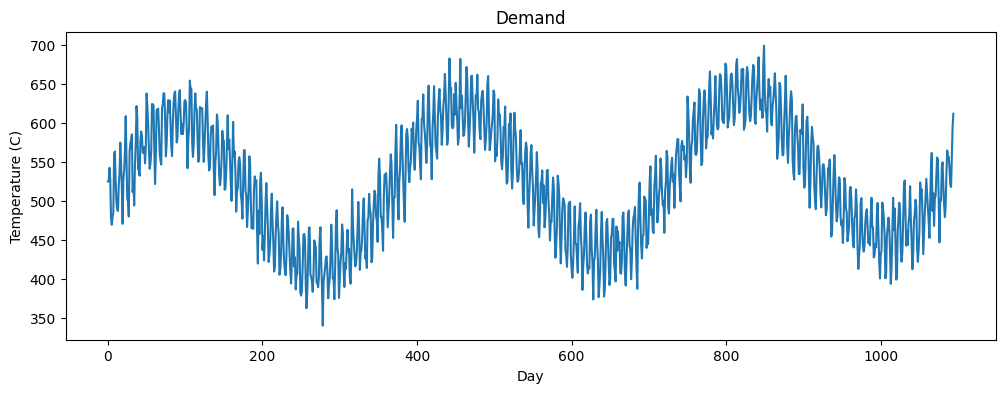

In [31]:
# YOUR CODE HERE
plt.plot(demand)
plt.title("Demand")
plt.xlabel("Day")
plt.ylabel("Temperature (C)")
plt.show()


**1b. (10 marks)** Split `demand` **in time order** into train (70%), validation (15%) and test (15%). Print the size of each part.

*Hint:* see Section 4 of Part 1.

In [32]:
n = len(demand)
train_end = int(0.70 * n)        # YOUR CODE HERE
val_end   = int(0.85 * n)        # YOUR CODE HERE

train_data = demand[:train_end]       # YOUR CODE HERE
val_data   = demand[train_end:val_end]       # YOUR CODE HERE
test_data  = demand[val_end:]       # YOUR CODE HERE

# print the three sizes
print("Train size:", len(train_data))
print("Validation size:", len(val_data))
print("Test size:", len(test_data))

Train size: 766
Validation size: 164
Test size: 165


**1c. (5 marks)** Scale the three parts with min-max scaling. Use the min and max of the **training data only**.

In [34]:
data_min = train_data.min()         # YOUR CODE HERE
data_max = train_data.max()         # YOUR CODE HERE

train_scaled = scale(train_data, data_min, data_max)
val_scaled = scale(val_data, data_min, data_max)    # YOUR CODE HERE
test_scaled = scale(test_data, data_min, data_max)      # YOUR CODE HERE

**1d. (10 marks)** Create sliding windows of size **14** (two weeks) for all three parts, convert them to tensors with `to_tensors`, and print the shapes of `X_train`, `y_train`, `X_val`, `y_val`, `X_test`, `y_test`.

In [35]:
WINDOW = 14

X_train, y_train = to_tensors(*create_windows(train_scaled, WINDOW))
X_val, y_val = to_tensors(*create_windows(val_scaled, WINDOW))
X_test, y_test = to_tensors(*create_windows(test_scaled, WINDOW))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)


X_train shape: torch.Size([752, 14, 1])
y_train shape: torch.Size([752, 1])


---
## Exercise 2: Train and compare RNN, LSTM and GRU (40 marks)

**2a. (15 marks)** Train an RNN, an LSTM and a GRU with these settings: `hidden_size=32`, `epochs=300`, `lr=0.01`. (This dataset has a weekly pattern as well as a yearly one, so it needs more epochs than Part 1.) Call `set_seed(42)` before creating each model.

For each model, save: the trained model, the list of training losses, the validation RMSE and the validation MAE. The skeleton below uses a loop and dictionaries so you only write the training code once.

In [36]:
models = {}
losses = {}
val_rmse = {}
val_mae = {}

for cell in ["RNN", "LSTM", "GRU"]:
    set_seed(42)
    model = Forecaster(cell, hidden_size=32)

    # Train the model
    model_losses = train_model(model, X_train, y_train, epochs=300, lr=0.01, print_every=0)

    # Evaluate on the validation set
    pred, true, rmse, mae = evaluate(model, X_val, y_val, data_min, data_max)

    # Save to dictionaries
    models[cell] = model
    losses[cell] = model_losses
    val_rmse[cell] = rmse
    val_mae[cell] = mae

    print(cell, "done")

RNN done
LSTM done
GRU done


**2b. (10 marks)** Make a pandas DataFrame with the columns `Model`, `Val RMSE`, `Val MAE` and `Parameters`, with one row for each model. Display it.

In [37]:
results_ex2 = pd.DataFrame({
    "Model": ["RNN", "LSTM", "GRU"],
    "Val RMSE": [val_rmse["RNN"], val_rmse["LSTM"], val_rmse["GRU"]],
    "Val MAE": [val_mae["RNN"], val_mae["LSTM"], val_mae["GRU"]],
    "Parameters": [
        count_parameters(models["RNN"]),
        count_parameters(models["LSTM"]),
        count_parameters(models["GRU"])
    ]
})
display(results_ex2.round(3))

,Model,Val RMSE,Val MAE,Parameters
0,RNN,16.942,13.231,1153
1,LSTM,20.867,16.631,4513
2,GRU,16.284,12.921,3393


**2c. (10 marks)** Plot the training loss curves of the three models in **one** figure. Use a log scale on the y-axis, and add a title, axis labels and a legend.

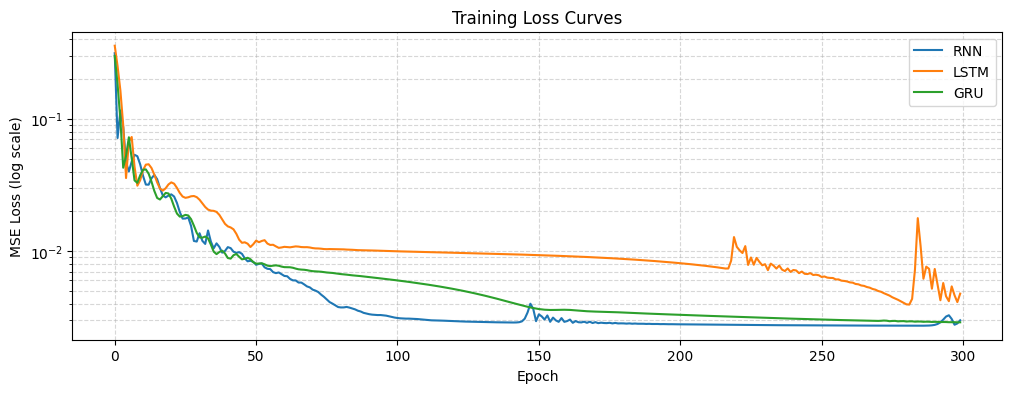

In [38]:
plt.plot(losses["RNN"], label="RNN")
plt.plot(losses["LSTM"], label="LSTM")
plt.plot(losses["GRU"], label="GRU")
plt.yscale("log")
plt.title("Training Loss Curves")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss (log scale)")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

**2d. (5 marks)** Which model has the lowest validation RMSE? Compare it with the other two models in terms of both error and number of parameters. (2 to 3 sentences)

**Your answer:**

---
## Exercise 3: Tune, test and explain (30 marks)

**3a. (10 marks)** Take the model type with the lowest validation RMSE in Exercise 2 (write it in `best_cell`). Train it again with `hidden_size` of **16** and **64** (keep all other settings the same: `epochs=300`, `lr=0.01` and call `set_seed(42)` before each model). Print the validation RMSE for each hidden size. Together with your result for hidden size 32 from Exercise 2, which hidden size is best?

In [39]:
best_cell = "GRU"

for hidden in [16, 64]:
    set_seed(42)
    model = Forecaster(best_cell, hidden_size=hidden)
    train_model(model, X_train, y_train, epochs=300, lr=0.01, print_every=0)
    _, _, rmse, mae = evaluate(model, X_val, y_val, data_min, data_max)
    print(f"hidden_size = {hidden:2d}   val RMSE = {rmse:.3f} MW")

hidden_size = 16   val RMSE = 18.801 MW
hidden_size = 64   val RMSE = 17.341 MW


**Your answer (best hidden size):** The best performing hidden size is 32

**3b. (10 marks)** Train your final model (`best_cell` with the best hidden size from 3a, `set_seed(42)`). Evaluate it on the **test set**, print the test RMSE and MAE, and plot the actual and predicted values for the first 100 test days in one figure (with title, axis labels and legend).

Test RMSE: 17.765 MW
Test MAE : 14.319 MW


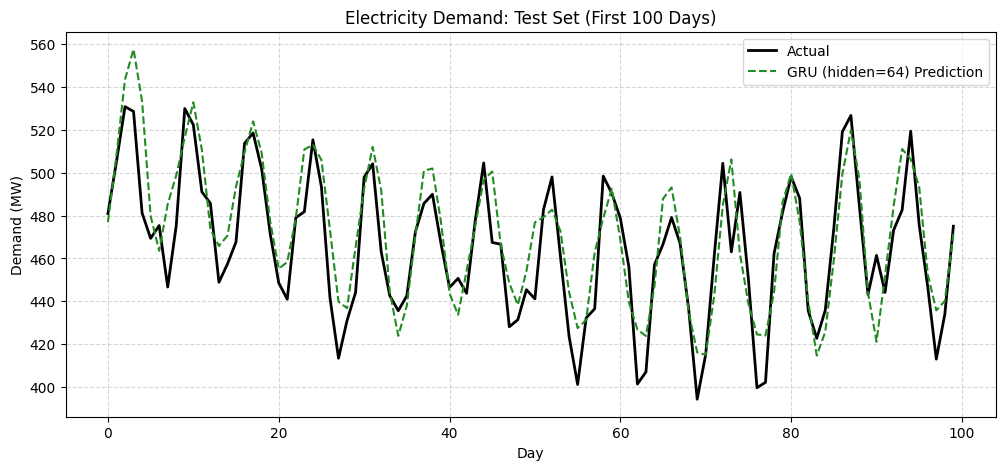

In [40]:
set_seed(42)
final_model = Forecaster("GRU", hidden_size=64)
train_model(final_model, X_train, y_train, epochs=300, lr=0.01, print_every=0)

# Evaluate on the test set
pred_test, true_test, rmse_test, mae_test = evaluate(final_model, X_test, y_test, data_min, data_max)
print(f"Test RMSE: {rmse_test:.3f} MW")
print(f"Test MAE : {mae_test:.3f} MW")

# Plot the actual and predicted values for the first 100 test days
plt.figure(figsize=(12, 5))
plt.plot(true_test[:100], label="Actual", color="black", linewidth=2)
plt.plot(pred_test[:100], label="GRU (hidden=64) Prediction", color="forestgreen", linestyle="--")
plt.title("Electricity Demand: Test Set (First 100 Days)")
plt.xlabel("Day")
plt.ylabel("Demand (MW)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

**3c. (10 marks)** Answer in your own words (2 to 3 sentences each).

**(i) (5 marks)** Why must we split a time series in time order instead of shuffling it randomly before splitting?

**Your answer:**


**(ii) (5 marks)** What problem does a simple RNN have with long sequences, and how do the gates in LSTM and GRU help with it?

**Your answer:**

### Exercise 3c(i) Answer

We must split a time series in time order because the order of the data matters and future values depend heavily on past values. If we shuffle the data randomly before splitting, we would allow the model to look at future information during training (data leakage), resulting in unrealistically high training performance but very poor generalization to real-world future forecasts.

### Exercise 3c(ii) Answer

A simple RNN suffers from the **vanishing gradient problem** when dealing with long sequences because gradients are continuously multiplied by small weight values as they backpropagate through time, making the weight updates for early steps virtually zero. LSTMs and GRUs introduce **learnable gates** (such as forget, input, and update gates) that regulate the flow of information; these gates act as linear highways that allow gradients and key historical memories to bypass multiplicative decay and propagate over long temporal distances without vanishing.